# 06. PyTorch İle Model Eğitimi (Model Training Steps)

Bu notebook'ta PyTorch kullanarak uçtan uca bir regresyon modelinin hazırlanmasını, `nn.Module` ile model mimarisinin tanımlanmasını, eğitilmemiş modelden `torch.inference_mode()` ile ilk tahminlerin (kör okçu) alınmasını, Kayıp Fonksiyonu (Loss) ve İyileştirici (Optimizer) tanımlanmasını, **5 Adımlı Eğitim Döngüsünü (Training Loop)** ve nihai model performansının değerlendirilmesini öğreniyoruz.

---
### 📌 İçindekiler
1. [Ortam Kurulumu ve Veri Yükleme](#1-ortam-kurulumu-ve-veri-yükleme)
2. [Verinin Hazırlanması & Eğitim/Test Ayrımı (Train-Test Split)](#2-verinin-hazırlanması--eğitimtest-ayrımı-train-test-split)
3. [PyTorch Model Mimarisi Oluşturma (nn.Module)](#3-pytorch-model-mimarisi-oluşturma-nnmodule)
4. [Eğitilmemiş Model İle İlk Tahminler (Inference Mode & Kör Okçu)](#4-eğitilmemiş-model-İle-İlk-tahminler-inference-mode--kör-okçu)
5. [Kayıp Fonksiyonu (Loss) ve İyileştirici (Optimizer)](#5-kayıp-fonksiyonu-loss-ve-İyileştirici-optimizer)
6. [Modelin Eğitilmesi (Training Loop - 5 Altın Adım)](#6-modelin-eğitilmesi-training-loop---5-altın-adım)
7. [Eğitim Sonuçlarının Görselleştirilmesi (Loss Curves)](#7-eğitim-sonuçlarının-görselleştirilmesi-loss-curves)
8. [Eğitilmiş Model İle Nihai Tahminler (Evaluation)](#8-eğitilmiş-model-İle-nihai-tahminler-evaluation)


## 1. Ortam Kurulumu ve Veri Yükleme


In [ ]:

import pandas as pd
import torch
import matplotlib.pyplot as plt

In [ ]:
# --- PyTorch Model Geliştirme Adımları ---
# 1. Veriyi hazırlamak (Data Preparation)
# 2. PyTorch model mimarisini kurmak (Model Building)
# 3. Eğitilmemiş model ile ilk tahminleri almak (Inference)
# 4. Kayıp Fonksiyonu ve İyileştirici tanımlamak (Loss & Optimizer)
# 5. Modeli eğitmek (Training Loop)
# 6. Modeli değerlendirmek ve kaydetmek (Evaluation & Saving)


In [ ]:
# 1. Adım: CSV dosyasından veri setini Pandas DataFrame olarak yüklüyoruz
df = pd.read_csv("06-study_hours_grades.csv")


In [5]:
df.head()

,study_hours,grade
0,3.745401,30.203939
1,9.507143,57.878452
2,7.319939,46.368401
3,5.986585,39.330717
4,1.560186,14.843888


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   study_hours  50 non-null     float64
 1   grade        50 non-null     float64
dtypes: float64(2)
memory usage: 932.0 bytes


In [6]:
df.describe()

,study_hours,grade
count,50.000000,50.000000
mean,4.459239,32.290305
std,2.888832,14.431931
min,0.205845,11.032281
25%,1.837670,21.062901
50%,4.360488,31.231858
75%,6.498549,41.683170
max,9.699099,60.573564


In [8]:
df['study_hours'].values # this is actually a numpy array, so we can convert this easily into tensors


array([3.74540119, 9.50714306, 7.31993942, 5.98658484, 1.5601864 ,
       1.5599452 , 0.58083612, 8.66176146, 6.01115012, 7.08072578,
       0.20584494, 9.69909852, 8.32442641, 2.12339111, 1.81824967,
       1.8340451 , 3.04242243, 5.24756432, 4.31945019, 2.9122914 ,
       6.11852895, 1.39493861, 2.92144649, 3.66361843, 4.56069984,
       7.85175961, 1.99673782, 5.14234438, 5.92414569, 0.46450413,
       6.07544852, 1.70524124, 0.65051593, 9.48885537, 9.65632033,
       8.08397348, 3.04613769, 0.97672114, 6.84233027, 4.40152494,
       1.22038235, 4.9517691 , 0.34388521, 9.09320402, 2.58779982,
       6.62522284, 3.11711076, 5.20068021, 5.46710279, 1.84854456])

In [10]:
# Pandas dizisini PyTorch tensörüne çeviriyoruz
torch.tensor(df['study_hours'].values)


tensor([3.7454, 9.5071, 7.3199, 5.9866, 1.5602, 1.5599, 0.5808, 8.6618, 6.0112,
        7.0807, 0.2058, 9.6991, 8.3244, 2.1234, 1.8182, 1.8340, 3.0424, 5.2476,
        4.3195, 2.9123, 6.1185, 1.3949, 2.9214, 3.6636, 4.5607, 7.8518, 1.9967,
        5.1423, 5.9241, 0.4645, 6.0754, 1.7052, 0.6505, 9.4889, 9.6563, 8.0840,
        3.0461, 0.9767, 6.8423, 4.4015, 1.2204, 4.9518, 0.3439, 9.0932, 2.5878,
        6.6252, 3.1171, 5.2007, 5.4671, 1.8485], dtype=torch.float64)

In [11]:
# Pandas dizisini PyTorch tensörüne çeviriyoruz
torch.tensor(df['study_hours'].values)


In [12]:
X

tensor([3.7454, 9.5071, 7.3199, 5.9866, 1.5602, 1.5599, 0.5808, 8.6618, 6.0112,
        7.0807, 0.2058, 9.6991, 8.3244, 2.1234, 1.8182, 1.8340, 3.0424, 5.2476,
        4.3195, 2.9123, 6.1185, 1.3949, 2.9214, 3.6636, 4.5607, 7.8518, 1.9967,
        5.1423, 5.9241, 0.4645, 6.0754, 1.7052, 0.6505, 9.4889, 9.6563, 8.0840,
        3.0461, 0.9767, 6.8423, 4.4015, 1.2204, 4.9518, 0.3439, 9.0932, 2.5878,
        6.6252, 3.1171, 5.2007, 5.4671, 1.8485], dtype=torch.float64)

In [13]:
y

tensor([30.2039, 57.8785, 46.3684, 39.3307, 14.8439, 16.3600, 11.9829, 55.4231,
        40.7430, 41.8775, 11.6774, 57.7253, 50.2683, 21.8403, 21.1532, 21.0328,
        23.5337, 35.6194, 32.2598, 26.5125, 39.6343, 16.6034, 22.3946, 25.9257,
        34.4286, 51.9713, 19.8397, 37.7188, 40.3440, 11.0323, 41.1000, 21.6023,
        13.1809, 60.5736, 53.0421, 52.0637, 25.4048, 14.2856, 44.3952, 28.0325,
        15.6626, 35.4731, 14.6752, 54.4295, 21.3220, 42.1226, 27.4164, 36.6609,
        36.2760, 20.2693], dtype=torch.float64)

In [14]:
#train -test split

## 2. Verinin Hazırlanması & Eğitim/Test Ayrımı (Train-Test Split)

> 💡 **Train / Test Split Mantığı:**
- Elimizdeki verinin **%80'ini** modeli eğitmek (`X_train`, `y_train`), **%20'sini** ise modelin hiç görmediği veriler üzerindeki başarısını test etmek (`X_test`, `y_test`) için ayırıyoruz.
- Pandas serilerini PyTorch'a aktarabilmek için önce `.values` ile NumPy dizisine, ardından `torch.tensor()` ile tensöre dönüştürüyoruz.


In [15]:
# Verisetinin %80'ini eğitim (train), %20'sini test seti olarak ayırıyoruz
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]


In [18]:
# Verisetinin %80'ini eğitim (train), %20'sini test seti olarak ayırıyoruz
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]


In [19]:
X_train

tensor([3.7454, 9.5071, 7.3199, 5.9866, 1.5602, 1.5599, 0.5808, 8.6618, 6.0112,
        7.0807, 0.2058, 9.6991, 8.3244, 2.1234, 1.8182, 1.8340, 3.0424, 5.2476,
        4.3195, 2.9123, 6.1185, 1.3949, 2.9214, 3.6636, 4.5607, 7.8518, 1.9967,
        5.1423, 5.9241, 0.4645, 6.0754, 1.7052, 0.6505, 9.4889, 9.6563, 8.0840,
        3.0461, 0.9767, 6.8423, 4.4015], dtype=torch.float64)

In [20]:
X_test

tensor([1.2204, 4.9518, 0.3439, 9.0932, 2.5878, 6.6252, 3.1171, 5.2007, 5.4671,
        1.8485], dtype=torch.float64)

In [21]:
y_train

tensor([30.2039, 57.8785, 46.3684, 39.3307, 14.8439, 16.3600, 11.9829, 55.4231,
        40.7430, 41.8775, 11.6774, 57.7253, 50.2683, 21.8403, 21.1532, 21.0328,
        23.5337, 35.6194, 32.2598, 26.5125, 39.6343, 16.6034, 22.3946, 25.9257,
        34.4286, 51.9713, 19.8397, 37.7188, 40.3440, 11.0323, 41.1000, 21.6023,
        13.1809, 60.5736, 53.0421, 52.0637, 25.4048, 14.2856, 44.3952, 28.0325],
       dtype=torch.float64)

In [22]:
y_test

tensor([15.6626, 35.4731, 14.6752, 54.4295, 21.3220, 42.1226, 27.4164, 36.6609,
        36.2760, 20.2693], dtype=torch.float64)

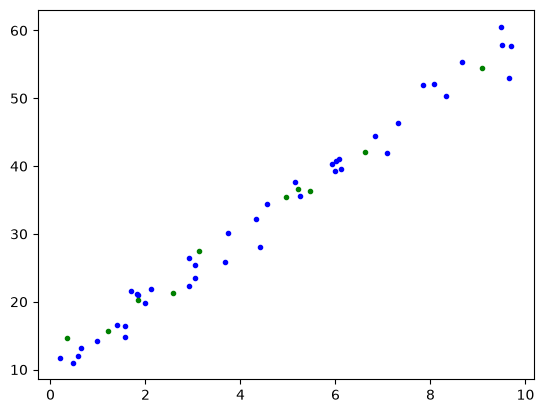

In [24]:
plt.scatter(X_train, y_train, c="b", s=9, label="Training data")
plt.scatter(X_test, y_test, c="g", s=9, label="Testing data")
plt.show()

In [30]:
#pytorch ann

# data is ready, now let's get to the second step
# but let's start with a very simple model without any training and see what it does

## 3. PyTorch Model Mimarisi Oluşturma (nn.Module)

> 🧠 **`nn.Module` Katman Yapısı:**
- PyTorch'ta tüm sinir ağları `nn.Module` sınıfından kalıtım (inheritance) alır.
- `__init__()` metodunda `super().__init__()` çağrılır ve eğitilebilir parametreler (`nn.Parameter`) tanımlanır.
- `requires_grad=True`: PyTorch'a bu parametrelerin türevinin (gradyanının) hesaplanacağını ve eğitim sırasında güncelleneceğini söyler.
- `forward(x)`: Verinin model içindeki ileriye doğru akış matematiğini ($Y = W \cdot X + b$) belirler.


In [31]:
from torch import nn

# PyTorch'ta tüm sinir ağları nn.Module sınıfından türetilir
class SimpleLinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        # nn.Parameter: Modeli eğitirken güncellenecek ağırlık (weight) ve yanlılık (bias) parametreleri
        # torch.randn(1): Rastgele başlangıç değerleri atar
        # requires_grad=True: PyTorch'a bu parametreler için gradyan (türev) hesaplanacağını söyler
        self.weights = nn.Parameter(torch.randn(1, dtype=torch.float), requires_grad=True)
        self.bias = nn.Parameter(torch.randn(1, dtype=torch.float), requires_grad=True)

    # forward(x): Verinin model içindeki ileriye doğru akış matematiği (y = weights * x + bias)
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.weights * x + self.bias


In [76]:
torch.manual_seed(42)

model_0 = SimpleLinearRegressionModel()
model_0 = torch.compile(model_0)

In [77]:
list(model_0.parameters())


[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [78]:
model_0.state_dict()


OrderedDict([('_orig_mod.weights', tensor([0.3367])),
             ('_orig_mod.bias', tensor([0.1288]))])

In [79]:
# Modelin rastgele oluşturulan başlangıç ağırlık (weights) ve yanlılık (bias) değerleri


## 4. Eğitilmemiş Model İle İlk Tahminler (Inference Mode & Kör Okçu)

> 🎯 **Neden Eğitilmemiş Modelden Tahmin Alıyoruz?**
- **Kör Okçu Analojisi:** Model başlangıçta tamamen rastgele `weights` ve `bias` değerleri seçti. Henüz eğitilmediği için ilk tahminlerin (kırmızı noktalar) gerçek hedeften (yeşil noktalar) ne kadar uzak olduğunu görmek istiyoruz.
- **`torch.inference_mode()`:** Tahmin alırken PyTorch'un türev/gradyan takibini kapatmasını sağlar. Belleği (RAM/VRAM) korur ve işlemleri hızlandırır.


In [80]:
# torch.inference_mode(): Gradyan takibini kapatıp eğitilmemiş modelden ilk tahminleri (kör okçu) alıyoruz
with torch.inference_mode():
    y_preds = model_0(X_test)


In [81]:
len(X_test)

10

In [82]:
len(X_test), len(y_preds)


(10, 10)

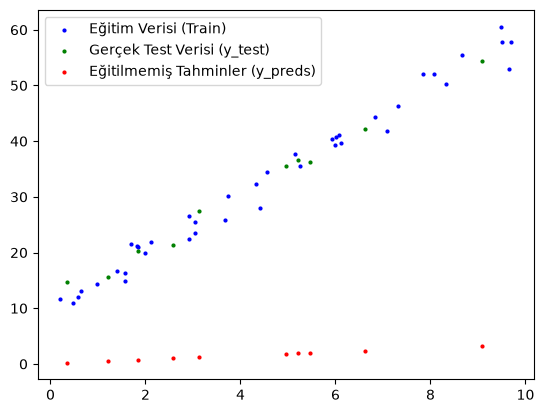

In [83]:
plt.scatter(X_train, y_train, c="b", s=4, label="Eğitim Verisi (Train)")
plt.scatter(X_test, y_test, c="g", s=4, label="Gerçek Test Verisi (y_test)")
plt.scatter(X_test, y_preds, c="r", s=4, label="Eğitilmemiş Tahminler (y_preds)")
plt.legend()
plt.show()
# Yeşil noktalar: Gerçek test değerleri
# Kırmızı noktalar: Eğitilmemiş modelin rastgele tahminleri
# Henüz modeli eğitmediğimiz için kırmızılar yeşillerle örtüşmez (bu normaldir)


In [84]:
# Göründüğü gibi tahminlerimiz henüz kötü, çünkü model eğitilmedi


In [85]:
# let's actually start with training


In [86]:
# before creating the training loop we have to define the optimizer and loss function


## 5. Kayıp Fonksiyonu (Loss) ve İyileştirici (Optimizer)

> 🛠️ **İki Temel Bileşen:**
1. **Loss Function (Kayıp Fonksiyonu):** Modelin tahminleri ile gerçek cevaplar arasındaki hatayı ölçer (Örn: `nn.MSELoss()` - Mean Squared Error veya `nn.L1Loss()` - Mean Absolute Error).
2. **Optimizer (İyileştirici):** Hesaplanan hataya bakarak modelin ağırlıklarını (`weights`) ve yanlılığını (`bias`) hangi adımlarla güncelleyeceğini belirler (Örn: `torch.optim.SGD` - Stochastic Gradient Descent, `lr` = Learning Rate / Öğrenme Oranı).


In [87]:
# Kayıp Fonksiyonu (Loss Function): MSE (Mean Squared Error - Ortalama Kare Hata)
loss_fn = nn.MSELoss()

# İyileştirici (Optimizer): SGD (Stochastic Gradient Descent), lr = 0.001 (Öğrenme Oranı)
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.001)


## 6. Modelin Eğitilmesi (Training Loop - 5 Altın Adım)

> 🔄 **Eğitim Döngüsünün (Training Loop) 5 Altın Adımı:**
1. **`model.train()`**: Modeli eğitim moduna alır.
2. **`y_pred = model(X_train)` (Forward Pass):** Model mevcut ağırlıklarla tahmin üretir.
3. **`loss = loss_fn(y_pred, y_train)` (Loss Calculation):** Tahminler ile gerçek değerler arasındaki hatayı hesaplar.
4. **`optimizer.zero_grad()` (Zero Gradients):** Önceki adımdan kalan gradyan sayaçlarını sıfırlar.
5. **`loss.backward()` (Backpropagation):** Hatayı modele geriye doğru yayarak parametrelerin türevini alır.
6. **`optimizer.step()` (Gradient Descent Step):** Türev değerine ve öğrenme oranına (`lr`) göre ağırlıkları ve bias'ı günceller.


In [88]:
torch.manual_seed(42)

# Epoch: Modelin tüm eğitim verisini kaç defa baştan sona işleyeceğini belirler
epochs = 120
train_loss_values = []
test_loss_values = []
epoch_count = []

for epoch in range(epochs):
    # 0. Modeli eğitim moduna alıyoruz (varsayılan moddur)
    model_0.train()

    # 1. Forward Pass: Girdi verisini modelden geçirip tahmin üretiyoruz
    y_pred = model_0(X_train)

    # 2. Kayıp Hesaplama: Tahminler ile gerçek veriler arasındaki hatayı hesaplıyoruz
    loss = loss_fn(y_pred, y_train)

    # 3. Gradyan Sıfırlama: Önceki epoch'tan kalan gradyan sayaçlarını sıfırlıyoruz
    optimizer.zero_grad()

    # 4. Geriye Yayılım (Backpropagation): Hataya göre parametrelerin türevini alıyoruz
    loss.backward()

    # 5. İyileştirici Adımı: Gradyan değerlerine göre weights ve bias'ı güncelliyoruz
    optimizer.step()

    # --- TEST / DEĞERLENDİRME ADIMI ---
    model_0.eval()
    with torch.inference_mode():
        test_pred = model_0(X_test)
        test_loss = loss_fn(test_pred, y_test.type(torch.float))

        if epoch % 5 == 0:
            epoch_count.append(epoch)
            train_loss_values.append(loss.detach().numpy())
            test_loss_values.append(test_loss.detach().numpy())
            print(f"Epoch: {epoch:3d} | Train Loss: {loss:.4f} | Test Loss: {test_loss:.4f}")


Epoch: 0 |  Train Loss: 1156.0767463081781 | Test Loss: 858.3089002392693 
Epoch: 5 |  Train Loss: 633.9334744710083 | Test Loss: 484.2838126795197 
Epoch: 10 |  Train Loss: 352.99125276114285 | Test Loss: 280.9052321188652 
Epoch: 15 |  Train Loss: 201.80191856738534 | Test Loss: 169.8918962041271 
Epoch: 20 |  Train Loss: 120.41268871324436 | Test Loss: 108.98032469406681 
Epoch: 25 |  Train Loss: 76.57232180621143 | Test Loss: 75.32371818092619 
Epoch: 30 |  Train Loss: 52.9314284286948 | Test Loss: 56.550341340290345 
Epoch: 35 |  Train Loss: 40.157054153236494 | Test Loss: 45.94531686432932 
Epoch: 40 |  Train Loss: 33.2285363195233 | Test Loss: 39.8529199979822 
Epoch: 45 |  Train Loss: 29.445092396910468 | Test Loss: 36.27478591424397 
Epoch: 50 |  Train Loss: 27.353849871049174 | Test Loss: 34.11266110941638 
Epoch: 55 |  Train Loss: 26.173215583708338 | Test Loss: 32.75872389060953 
Epoch: 60 |  Train Loss: 25.482771128378353 | Test Loss: 31.873639956137765 
Epoch: 65 |  Train

## 7. Eğitim Sonuçlarının Görselleştirilmesi (Loss Curves)

> 📉 **Kayıp Eğrisi (Loss Curve) İncelemesi:**
- Epoch sayısı arttıkça `Train Loss` (Eğitim Kaybı) ve `Test Loss` (Test Kaybı) değerlerinin hızla düştüğünü görüyoruz.
- Hatamız 1156 seviyesinden 23 seviyesine gerilemiştir. Bu da modelin verideki örüntüyü başarıyla öğrendiğini gösterir.


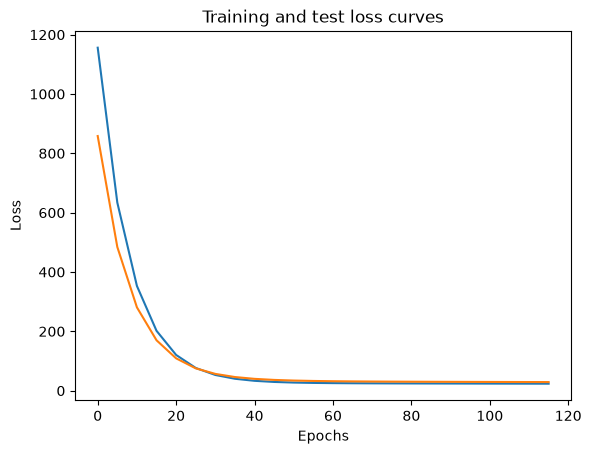

In [89]:
# Eğitim ve Test Kayıp (Loss) eğrilerini çizdiriyoruz
plt.plot(epoch_count, train_loss_values, label="Eğitim Kaybı (Train Loss)")
plt.plot(epoch_count, test_loss_values, label="Test Kaybı (Test Loss)")
plt.title("Eğitim ve Test Kayıp Eğrileri")
plt.ylabel("Kayıp (Loss)")
plt.xlabel("Epoch Sayısı")
plt.legend()
plt.show()


In [68]:
# what did this model come up with?


In [69]:
# Eğitilmiş modelin güncellenmiş ağırlık (weights) ve yanlılık (bias) değerleri
print(model_0.state_dict())


OrderedDict({'_orig_mod.weights': tensor([6.2166]), '_orig_mod.bias': tensor([2.2045])})


In [70]:
# let's actually make a prediction one more time with the trained model


## 8. Eğitilmiş Model İle Nihai Tahminler (Evaluation)

> 🎉 **Eğitilmiş Modelin Başarısı:**
- Başlangıçta rastgele atanan `weights` (0.3367) ve `bias` (0.1288) değerleri, 120 epoch sonunda yaklaşık **weights $\approx$ 6.21** ve **bias $\approx$ 2.20** değerlerine güncellenmiştir.
- Grafikte kırmızı renkte gösterilen eğitilmiş tahminler (`y_preds`), yeşil renkteki gerçek test değerlerinin (`y_test`) tam üzerine oturmuştur!


In [71]:
model_0.eval()
with torch.inference_mode():
  y_preds = model_0(X_test)

In [72]:
y_preds

tensor([ 9.7911, 32.9875,  4.3423, 58.7331, 18.2917, 43.3907, 21.5822, 34.5349,
        36.1912, 13.6961], dtype=torch.float64)

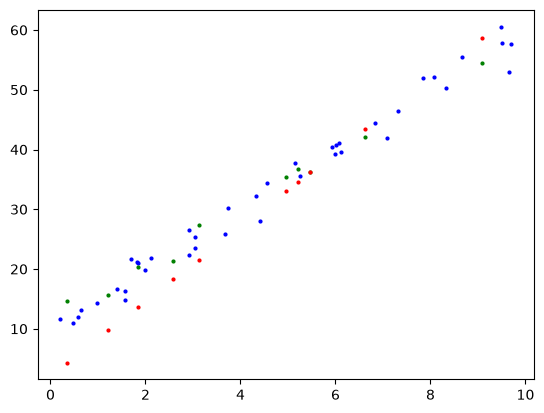

In [73]:
# Eğitilmiş model ile yapılan nihai tahminlerin görselleştirilmesi
plt.scatter(X_train, y_train, c="b", s=4, label="Eğitim Verisi (Train)")
plt.scatter(X_test, y_test, c="g", s=4, label="Gerçek Test Verisi (y_test)")
plt.scatter(X_test, y_preds, c="r", s=4, label="Eğitilmiş Tahminler (y_preds)")
plt.legend()
plt.show()
# Kırmızı noktalar (eğitilmiş tahminler) yeşil noktaların (gerçekler) üzerine tam oturdu!


In [74]:
# obviously we should make this much more elegant code-wise but it's a start to understand how nn works


---
### 📌 06. PyTorch Model Eğitimi Temelleri - Özet Cheat Sheet

| Kavram | Fonksiyon / Yapı | Açıklama |
| :--- | :--- | :--- |
| **Model Mirası** | `class Model(nn.Module):` | Tüm PyTorch modelleri `nn.Module` sınıfından türetilir |
| **İleri Akış** | `def forward(self, x):` | Girdinin model çıktısına dönüşme matematiği |
| **Parametre Takibi**| `requires_grad=True` | Ağırlıkların gradyan inişi ile güncelleneceğini belirtir |
| **Tahmin Modu** | `with torch.inference_mode():` | Gradyan takibini kapatır, hızlı tahmin alır |
| **Kayıp Fonksiyonu**| `nn.MSELoss()` / `nn.L1Loss()` | Tahmin ile gerçek değer arasındaki hatayı hesaplar |
| **İyileştirici** | `torch.optim.SGD(params, lr)` | Hataya göre ağırlıkları güncelleyen algoritma |
| **Eğitim Döngüsü** | `train() -> forward -> loss -> zero_grad -> backward -> step` | Derin öğrenme eğitiminin 5 altın adımı |
| **Değerlendirme** | `model.eval() + inference_mode()` | Modeli test moduna alır ve tahmin üretir |
